# LMNDM metastatic scoring from a nodule CSV

This notebook computes the case-level metastatic score of annotated pulmonary nodules and grades each nodule as Benign, Indeterminate, or Metastatic. Nodule centers are read from a CSV file, and nodules sharing a CT image form one case. Each nodule is shown on a cropped axial slice through its center, labelled with its primary tumor, density type, reference label, metastatic score, and predicted class.

The CSV needs `image_path`, `x`, `y`, `z`, `width`, `height`, `Primary tumor`, `density_type`, and `Label` columns, with coordinates in physical millimetres. `image_path` may point to another machine: a path that does not exist locally is resolved as `IMAGE_ROOT/<case folder>/<file name>`. Set `LMNDM_MODEL_DIR`, `LMNDM_NODULE_CSV`, and `LMNDM_IMAGE_ROOT` to override the defaults.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt

from LMNDM import MetastasisClassifier, group_cases, read_nodules, score_case
from LMNDM.detection.preprocessing import read_image
from LMNDM.runtime import configure_threads, resolve_device
from LMNDM.visualization import show_nodules

In [2]:
PROJECT_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "pyproject.toml").is_file()
        and (parent / "LMNDM").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from the LMNDM project directory.")

MODEL_ROOT = Path(
    os.environ.get("LMNDM_MODEL_DIR", PROJECT_ROOT / "models")
).expanduser()
CSV_PATH = Path(
    os.environ.get(
        "LMNDM_NODULE_CSV",
        PROJECT_ROOT / "data/example/nodules.csv",
    )
).expanduser()
IMAGE_ROOT = Path(
    os.environ.get("LMNDM_IMAGE_ROOT", CSV_PATH.parent)
).expanduser()
DEVICE = "auto"       # auto, cpu, mps, cuda, or cuda:0
NUM_THREADS = 2

if not CSV_PATH.is_file():
    raise FileNotFoundError("Set LMNDM_NODULE_CSV to a readable nodule CSV.")
if not MODEL_ROOT.is_dir():
    raise FileNotFoundError(
        "Set LMNDM_MODEL_DIR to the extracted model directory."
    )

In [3]:
nodules = read_nodules(CSV_PATH)
cases = group_cases(nodules, IMAGE_ROOT)
print(f"{len(nodules)} nodules in {len(cases)} cases")

21 nodules in 4 cases


In [4]:
device = resolve_device(DEVICE)
configure_threads(NUM_THREADS)
classifier = MetastasisClassifier(
    MODEL_ROOT / "metastasis_classification" / "model.pth",
    MODEL_ROOT / "metastasis_classification" / "label_index.csv",
    device=device,
)
print("Selected device:", device)

Selected device: mps


Case 1: 3 nodules


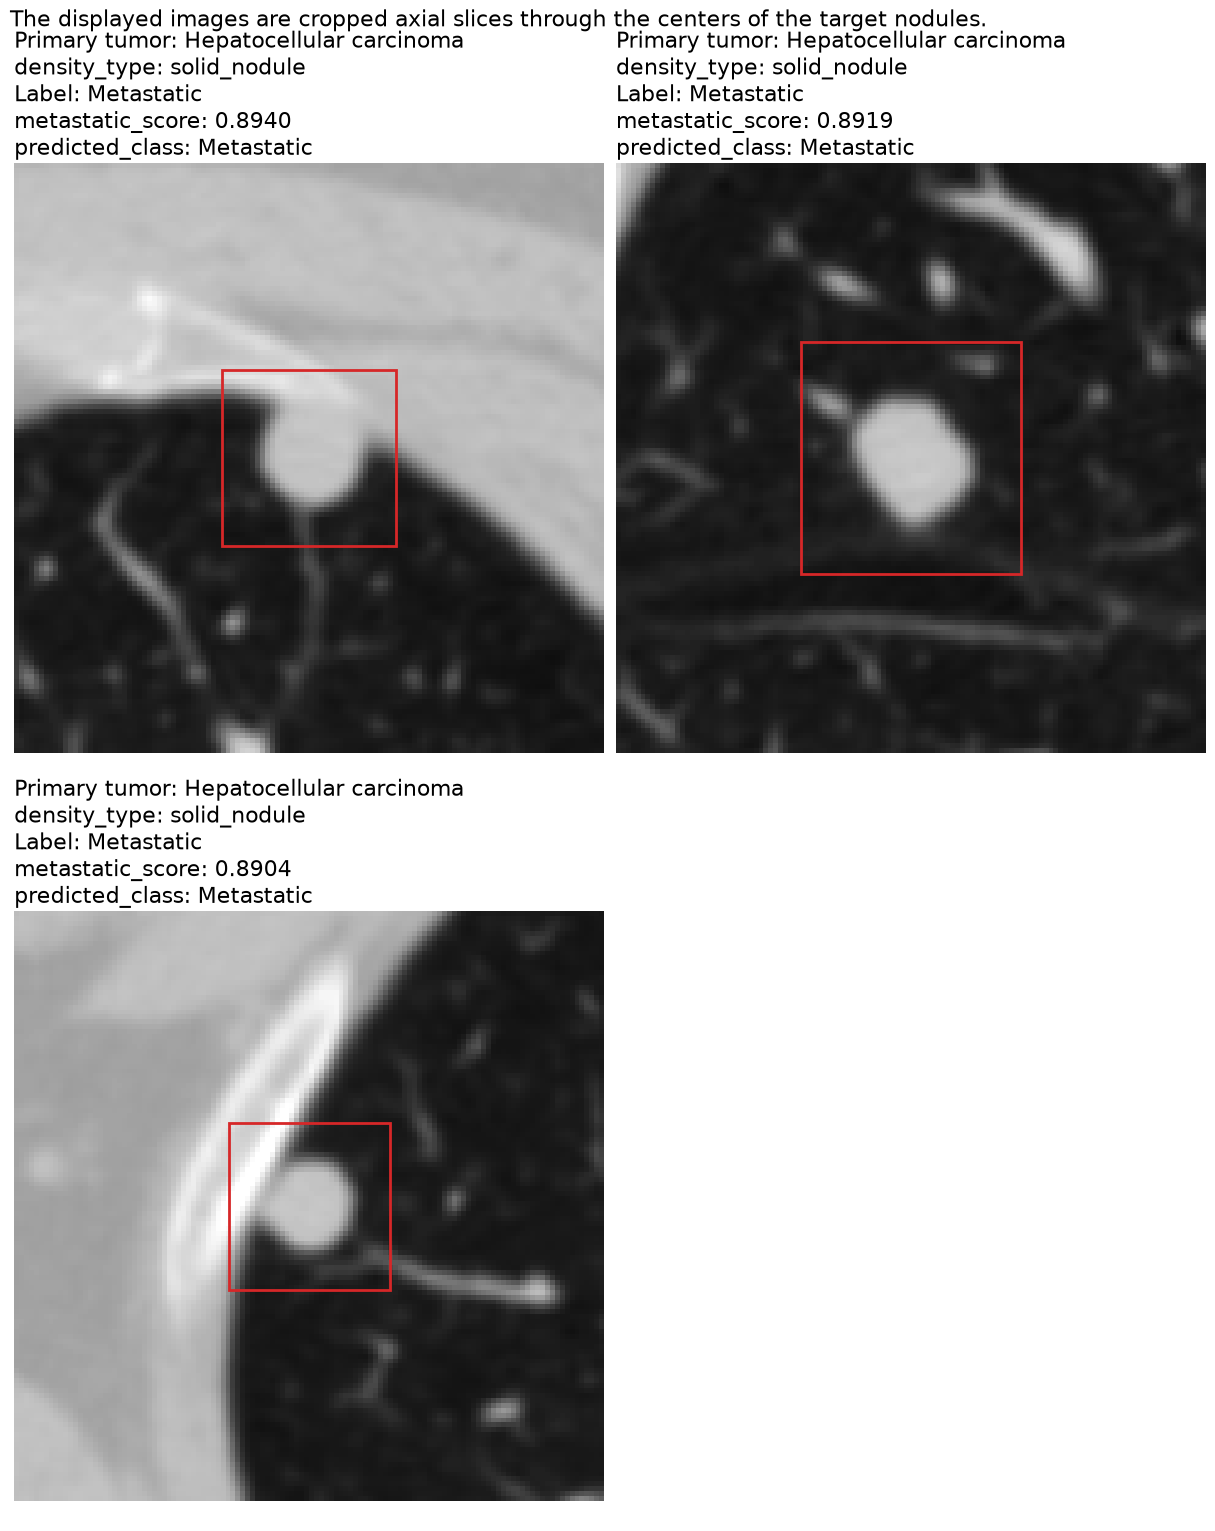

Case 2: 8 nodules


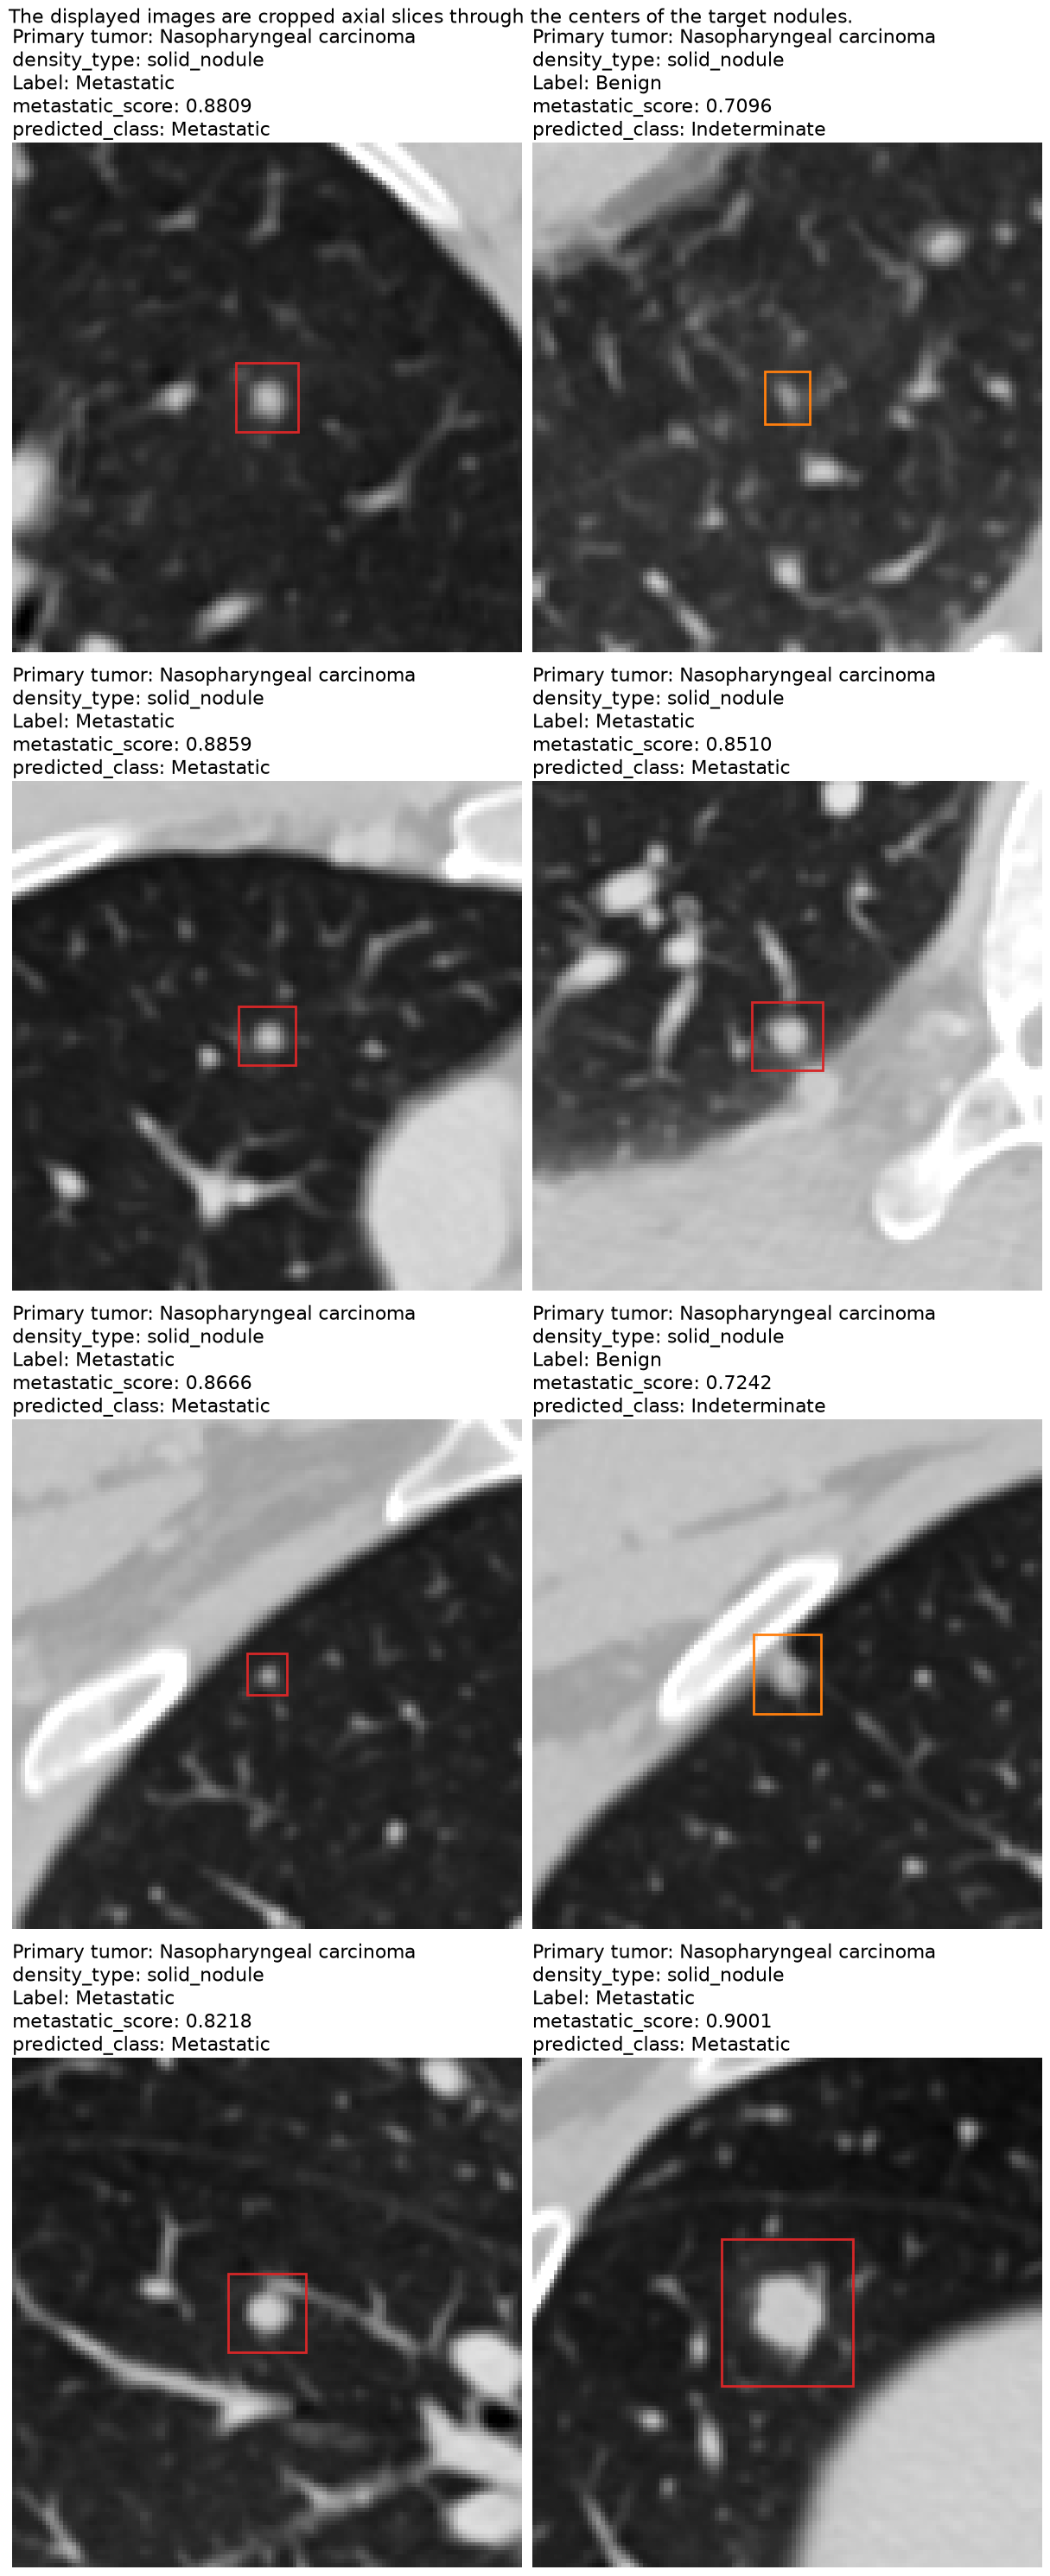

Case 3: 3 nodules


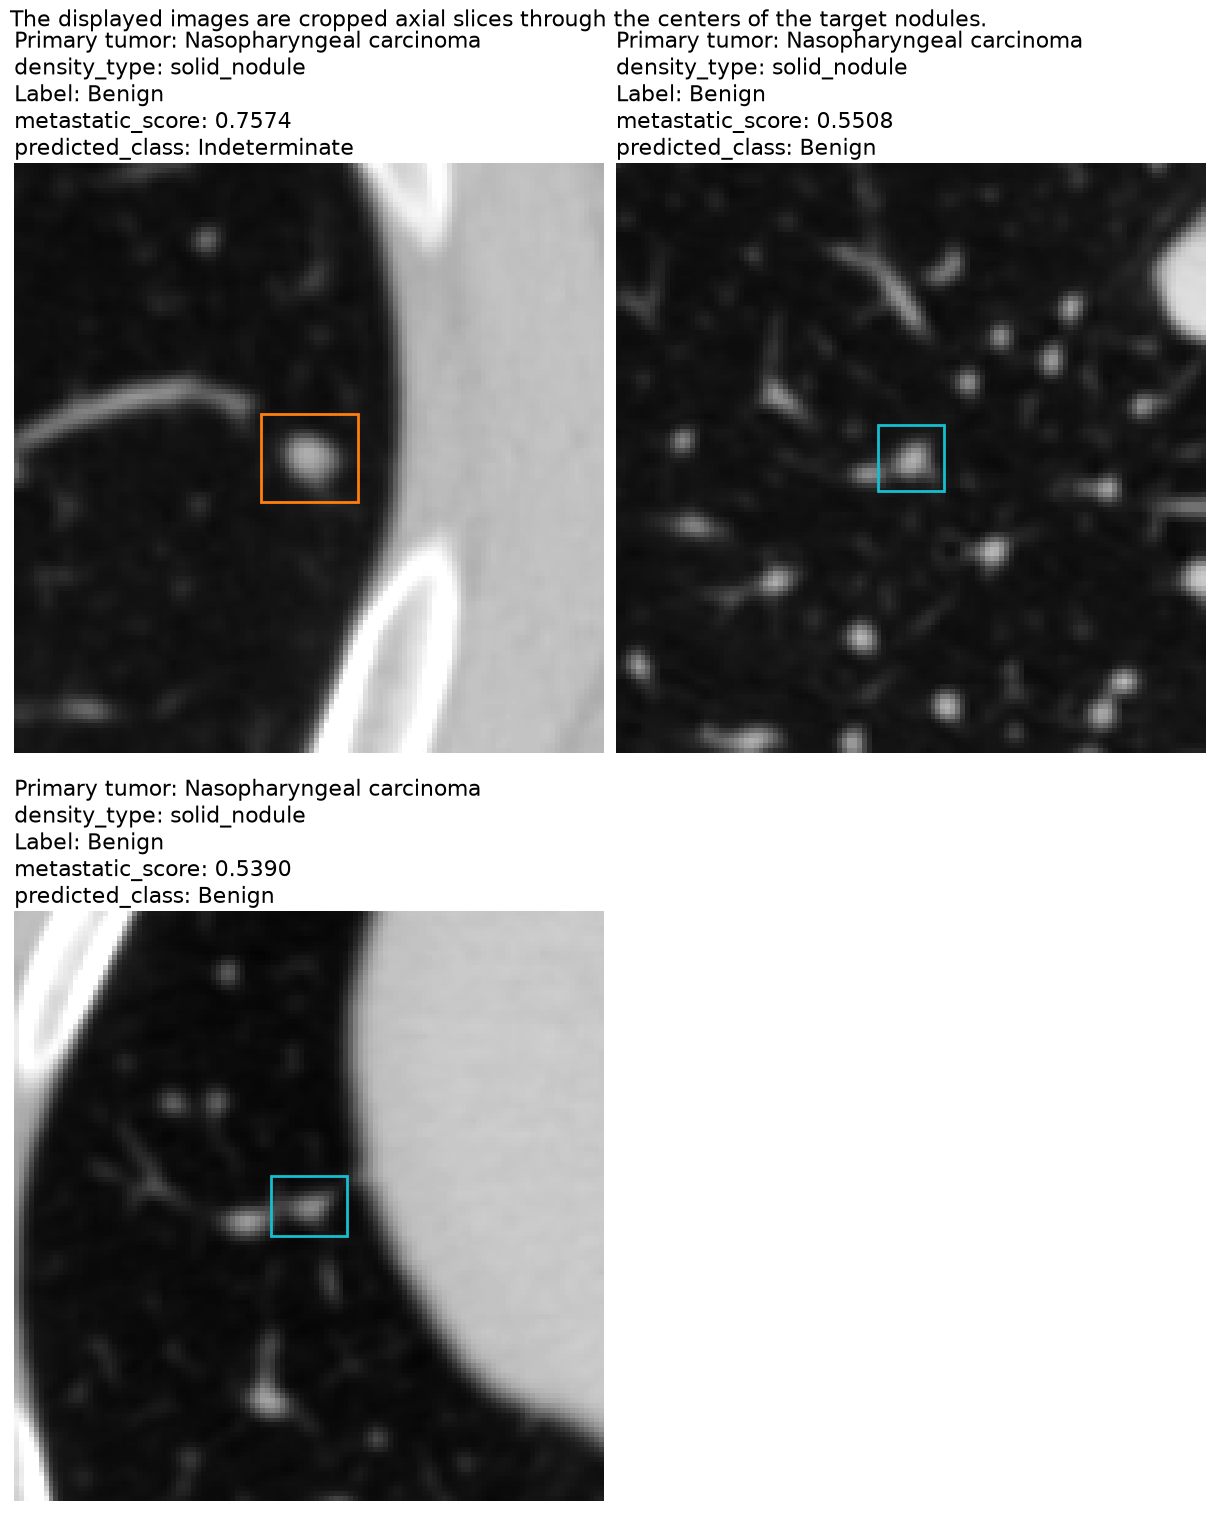

Case 4: 7 nodules


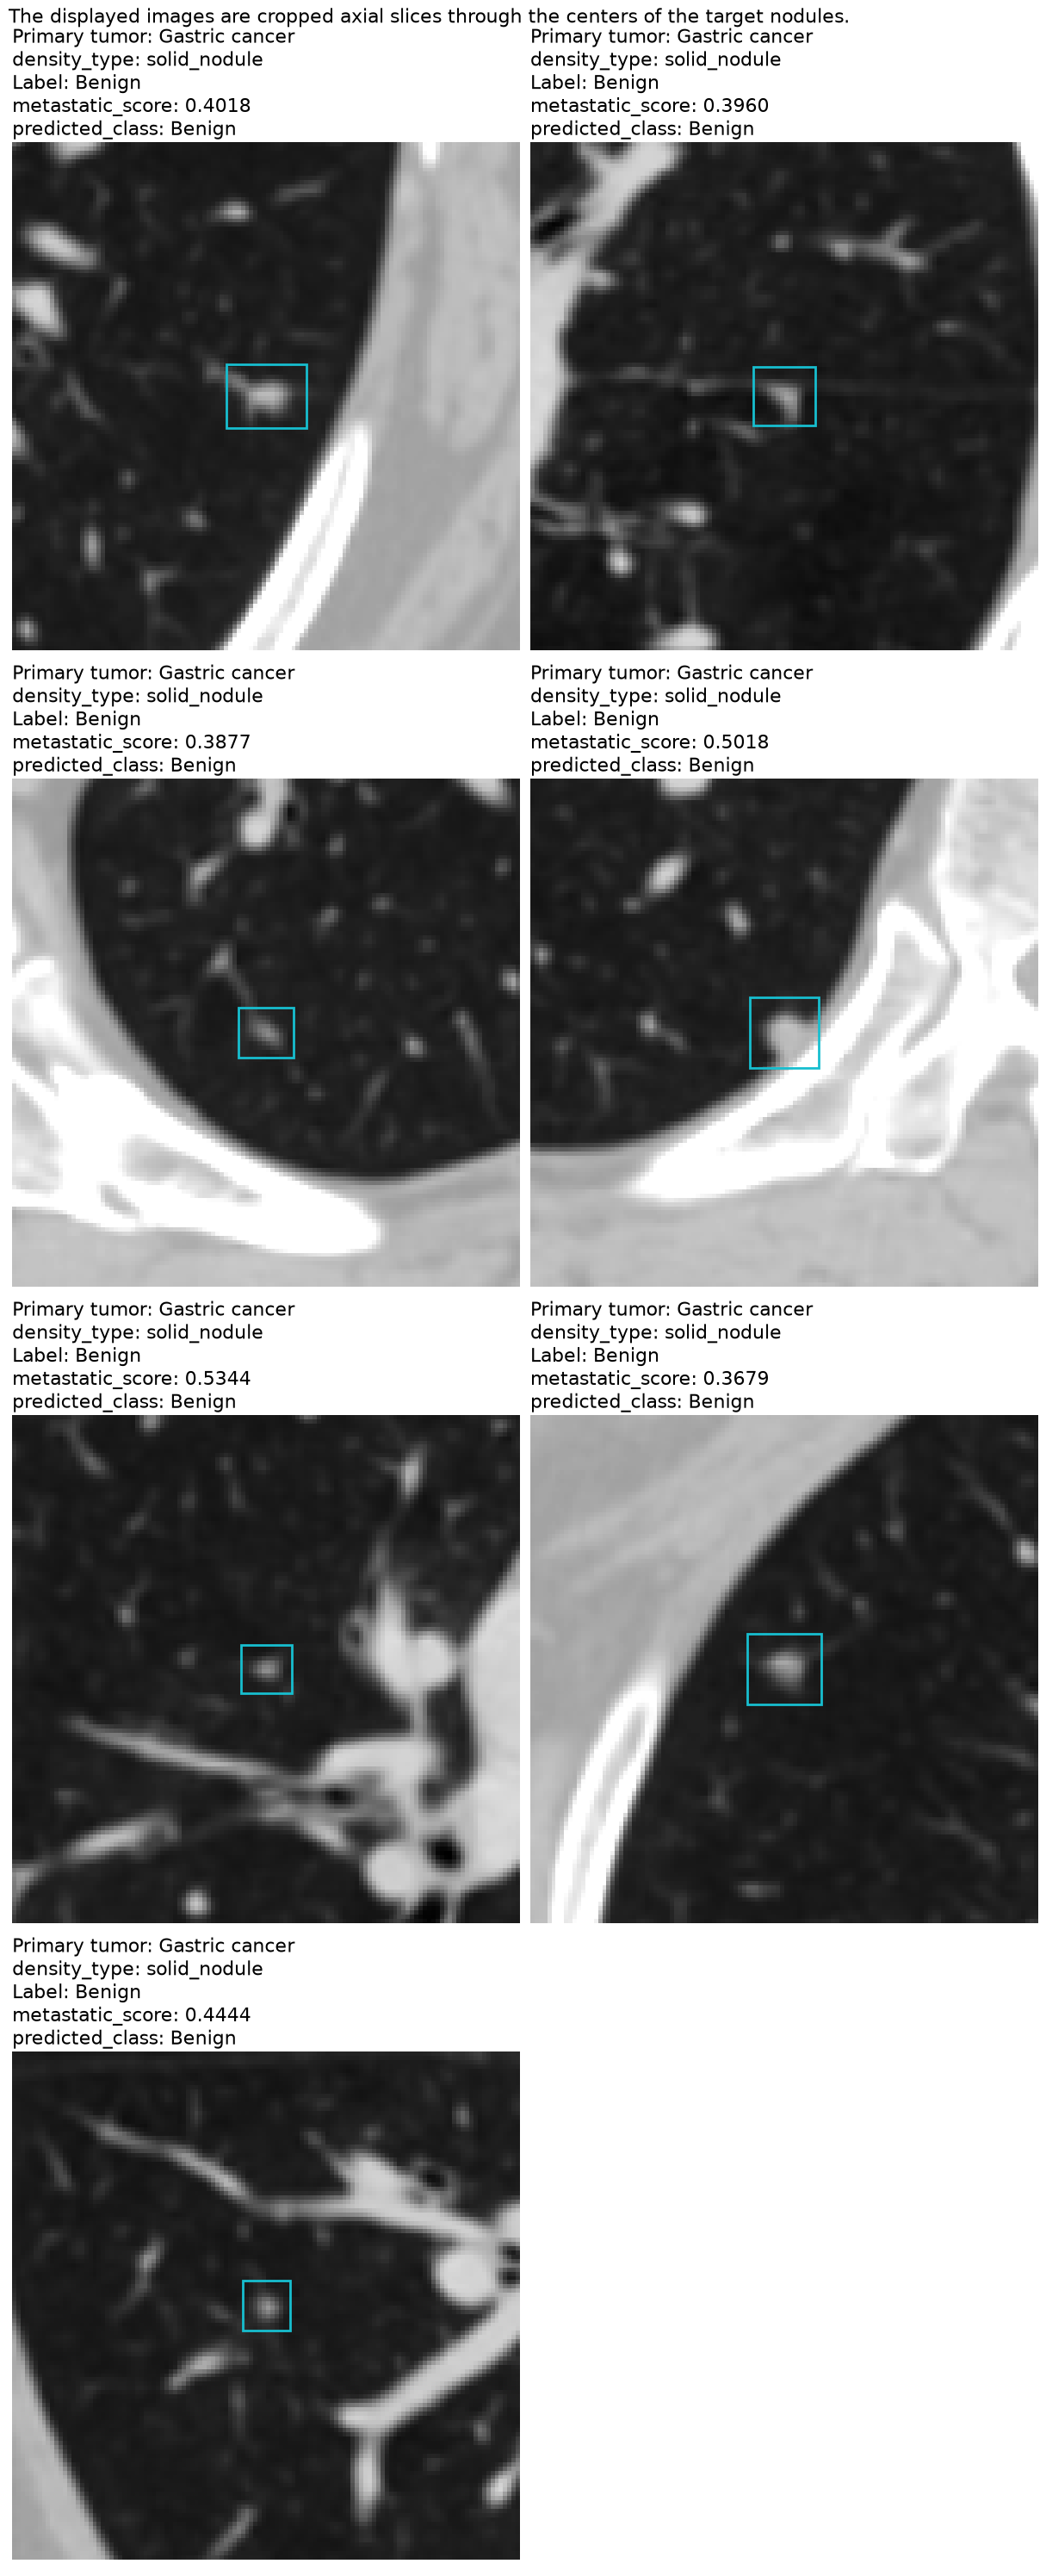

In [5]:
for case_index, (image_path, case_nodules) in enumerate(cases.items(), start=1):
    image = read_image(image_path)
    score_case(classifier, image, case_nodules)

    print(f"Case {case_index}: {len(case_nodules)} nodules")
    show_nodules(image, case_nodules, columns=2)
    plt.show()